# Dynamic FER Prediction Comparison

Compare image-sequence and FEA-sequence predictions by expression and camera view. The CSV is read from a fixed commit of `emohevrdb-dfer`.

Requirements: NumPy, pandas, seaborn, and Matplotlib. Run all cells in order. The generated PDF is saved in the working directory.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load predictions

In [2]:
COMMIT = "3993b6813443e75eff8f380e9d4c1b1d6810221c"
CSV_URL = (
    "https://raw.githubusercontent.com/thorbenortmann/emohevrdb-dfer/"
    f"{COMMIT}/5_dynamic_facial_expression_recognition/dynamic_test_predictions.csv"
)

predictions = pd.read_csv(CSV_URL)
CLASS_NAMES = ["Anger", "Disgust", "Fear", "Happiness", "Neutral", "Sadness", "Surprise"]

## Count prediction outcomes

Each reenactment contributes one comparison per camera view. The four outcomes are both correct, only FEA correct, only image correct and both incorrect. Oracle accuracy counts cases where at least one prediction is correct.


In [3]:
OUTCOMES = ["both_correct", "fea_only", "image_only", "both_wrong"]
OUTCOME_LABELS = ["Both correct", "Only FEA correct", "Only image correct", "Both incorrect"]

image_correct = predictions["image_pred_id"].eq(predictions["true_label_id"])
fea_correct = predictions["fea_pred_id"].eq(predictions["true_label_id"])

comparison = pd.DataFrame({
    "Emotion": predictions["true_label"],
    "Camera": predictions["camera_index"],
    "Outcome": np.select(
        [image_correct & fea_correct, ~image_correct & fea_correct, image_correct & ~fea_correct],
        OUTCOMES[:3], default="both_wrong",
    ),
})

index = pd.MultiIndex.from_product([CLASS_NAMES, [0, 1]], names=["Emotion", "Camera"])
counts = (
    comparison.groupby(["Emotion", "Camera", "Outcome"]).size()
    .unstack("Outcome", fill_value=0)
    .reindex(index=index, columns=OUTCOMES, fill_value=0)
)

totals = counts.sum()
print(pd.Series(totals.to_numpy(), index=OUTCOME_LABELS).to_string())
oracle_correct = totals.iloc[:3].sum()
print(f"Oracle accuracy: {oracle_correct}/{len(predictions)} = {oracle_correct / len(predictions):.2%}")

Both correct          476
Only FEA correct      116
Only image correct     74
Both incorrect         90
Oracle accuracy: 666/756 = 88.10%


## Plot and export

Green denotes both correct, light orange only FEA correct, blue only image correct and dark orange both incorrect. Camera labels are `c` for central and `s` for side. Counts greater than two are annotated.


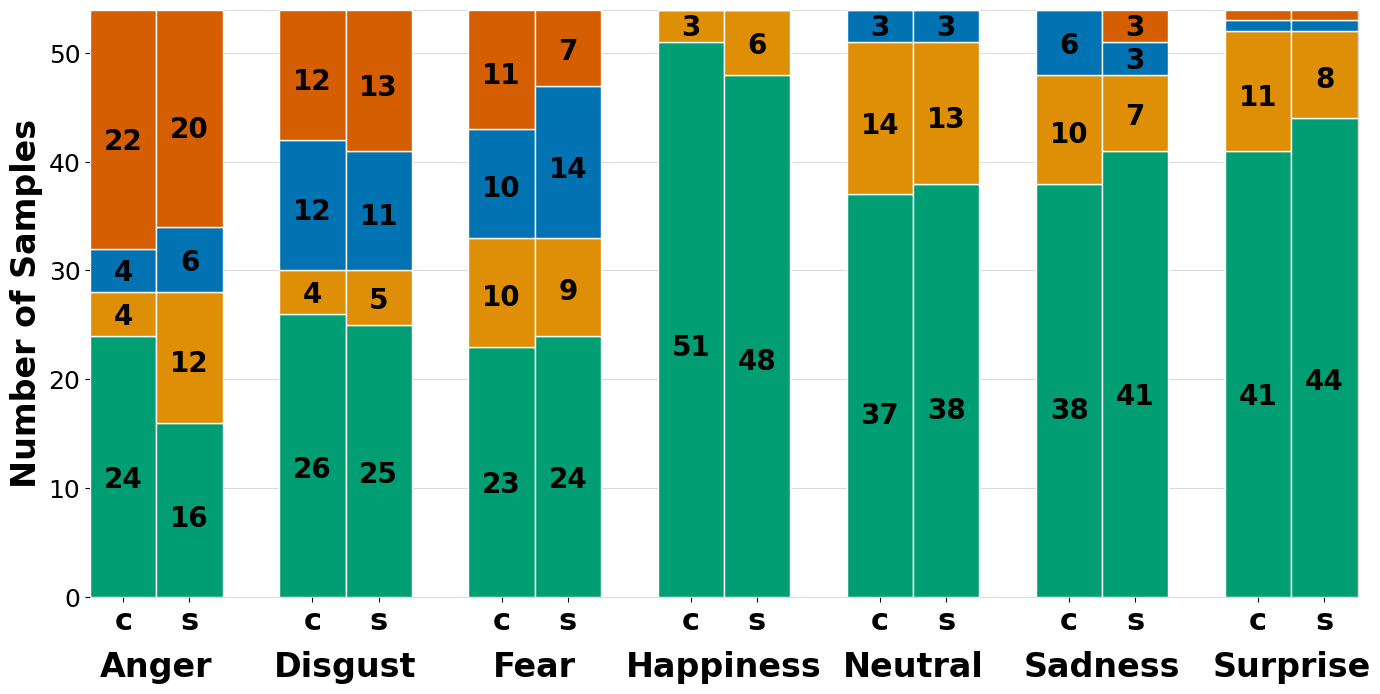

In [4]:
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

emotions = sorted(CLASS_NAMES)

colors = sns.color_palette("colorblind", n_colors=len(OUTCOMES))
colors = [colors[2], colors[1], colors[0], colors[3]]

fig, ax = plt.subplots(figsize=(14, 7))
ax.set_facecolor("white")

ax.set_axisbelow(True)
ax.grid(
    True,
    axis="y",
    which="both",
    linestyle="-",
    linewidth=0.6,
    color="lightgray",
    zorder=0,
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("lightgray")
    spine.set_linewidth(0.6)

width = 0.35
x = np.arange(len(emotions))

for camera in [0, 1]:
    camera_counts = counts.xs(camera, level="Camera").reindex(emotions)
    bottom = np.zeros(len(emotions))

    for outcome, color in zip(OUTCOMES, colors):
        values = camera_counts[outcome].to_numpy()

        bars = ax.bar(
            x + (camera - 0.5) * width,
            values,
            width,
            bottom=bottom,
            color=color,
            edgecolor="white",
            linewidth=1.0,
            zorder=3,
        )
        bottom += values

        for bar in bars:
            height = bar.get_height()
            if height > 1:
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_y() + height * 0.9 / 2,
                    str(int(height)),
                    ha="center",
                    va="center",
                    fontsize=20,
                    color="black",
                    fontweight="bold",
                    zorder=4,
                )

ax.set_ylabel("Number of Samples", fontsize=24, fontweight="bold")
ax.tick_params(axis="y", labelsize=18)

xticks = []
xticklabels = []

for position in x:
    xticks.extend([position - width / 2, position + width / 2])
    xticklabels.extend(["c", "s"])

ax.set_xticks(xticks)
ax.set_xticklabels(xticklabels, fontsize=22, fontweight="bold")

for position, emotion in zip(x, emotions):
    ax.text(
        position,
        -5,
        emotion,
        ha="center",
        va="top",
        fontsize=24,
        fontweight="bold",
    )

ax.set_xlim(x[0] - width, x[-1] + width)

plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig("prediction_comparison_thesis_dynamic.pdf", format="pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()
plt.close(fig)